# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa selisih rata-rata jumlah penyewaan sepeda per jam (`cnt`) antara kondisi cuaca cerah, berkabut, dan hujan/salju sepanjang 2011-2012, serta pada rentang suhu (°C) berapa rata-rata penyewaan per jam paling tinggi?
- **Pertanyaan 2:** Pada jam berapa puncak penyewaan terjadi di hari kerja dibandingkan hari libur selama 2012, dan berapa proporsi pengguna *casual* dan *registered* pada masing-masing tipe hari?
- **Pertanyaan 3:** Berapa persentase pertumbuhan total penyewaan bulanan pada 2012 dibandingkan bulan yang sama di 2011, dan pada bulan apa pertumbuhannya paling tinggi?

> **Catatan:** analisis menggunakan data per jam (`hour.csv`). Hari libur didefinisikan sebagai `workingday = 0` (akhir pekan dan hari libur nasional).

## Import Semua Packages/Library yang Digunakan

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})

## Data Wrangling

### Gathering Data

#### Load df ...

In [4]:
hour_df= pd.read_csv('hour.csv')
print("Ukuran data (baris, kolom):", hour_df.shape)
hour_df.head()

Ukuran data (baris, kolom): (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Data berisi 17.379 baris (catatan per jam) dan 17 kolom, mencakup periode 1 Januari 2011 sampai 31 Desember 2012.
- Kolom `cnt` adalah total penyewaan, yaitu penjumlahan `casual` dan `registered`.
- Kolom `season`, `yr`, `mnth`, `weekday`, dan `weathersit` masih berupa kode angka, sedangkan `temp`, `atemp`, `hum`, dan `windspeed` masih berupa nilai ternormalisasi.

### Assessing Data

#### Identifying missing value, duplicate data dan tipe data

In [5]:
hour_df.info()
print('\nJumlah Missing Values perkolom: ')
print(hour_df.isna().sum())
print('\n Jumlah data Duplikat: ', hour_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Jumlah Missing Values perkolom: 
instant       0

#### Identifying invalid value dan kelengkapan data

In [8]:
# 1. kelembapan = 0 tidak masuk akal secara fisik
hum_nol = hour_df[hour_df['hum']==0]
print('Baris dengan hum = 0 : ', len(hum_nol))
print('Tanggal terkait      : ', hum_nol["dteday"].unique())

#2. Kecepatan angin 0
print('\nBaris dengan windspeed = 0 :', (hour_df["windspeed"]==0).sum())

#3. Konsistensi cnt = casual + registered
print("\nBaris dengan cnt != casual + registered :",
        (hour_df['cnt']!= hour_df['casual'] + hour_df["registered"]).sum())

# 4. Kelengkapan catatan perhari (seharusnya 24 jam)
jam_per_hari = hour_df.groupby("dteday").size()
print("\nJumlah hari   :", jam_per_hari.size)
print('Hari dengan < 24   :', (jam_per_hari< 24).sum())


Baris dengan hum = 0 :  22
Tanggal terkait      :  ['2011-03-10']

Baris dengan windspeed = 0 : 2180

Baris dengan cnt != casual + registered : 0

Jumlah hari   : 731
Hari dengan < 24   : 76


#### Identifying outlier

In [9]:
kolom_outlier = ['casual', 'registered', 'cnt', "windspeed"]
hasil = []
for kolom in kolom_outlier:
  q1, q3 = hour_df[kolom].quantile([0.25, 0.75])
  iqr = q3-q1
  batas_bawah = q1 - 1.5 * iqr
  batas_atas = q3 + 1.5 * iqr
  hasil.append({"kolom": kolom,
                  "batas_bawah_IQR": round(batas_bawah, 2),
                  "batas_atas_IQR": round(batas_atas, 2),
                  "outlier_bawah": (hour_df[kolom] < batas_bawah).sum(),
                  "outlier_atas": (hour_df[kolom] > batas_atas).sum(),
                  "nilai_min": hour_df[kolom].min(),
                  "nilai_max": hour_df[kolom].max()})
pd.DataFrame(hasil)

,kolom,batas_bawah_IQR,batas_atas_IQR,outlier_bawah,outlier_atas,nilai_min,nilai_max
0,casual,-62.00,114.00,0,1192,0.0,367.0000
1,registered,-245.00,499.00,0,680,0.0,886.0000
2,cnt,-321.50,642.50,0,505,1.0,977.0000
3,windspeed,-0.12,0.48,0,342,0.0,0.8507


**Steps to Take:**
- Tidak ada missing value maupun data duplikat, sehingga tidak perlu penanganan untuk keduanya.
- Tipe data tidak sesuai: `dteday` masih bertipe teks sehingga perlu dibuah menjadi `datetime`.
- Nilai tidak akurat (inacurate/invalid value): Terdapat 22 baris dengan hum = 0, seluruhnya terjadi pada tanggal 10 Maret 2011. Nilai ini perlu diganti dengan median kelembapan pada bulan dan tahun yang sama.
- Nilai kategorikal berupa kode angka : `season`, `yr`, `mnth`, `weekday` dan `weathersit` dipetakan menjadi label yang mudah dibaca. Kategori cuaca 4 (hujan lebat) hanya berisi 3 baris, sehingga digabung dengan kategori 3 menjadi grup Hujan/Salju.
- Nilai ternormalisasi: `temp`, `atemp`, `hum`, dan `windspeed` dikembalikan ke skala asli (×41, ×50, ×100, ×67).
- Outlier: terdapat outlier pada `casual`, `registered`, `cnt`, dan `windspeed`. Outlier pada kolom penyewaan merupakan lonjakan permintaan jam sibuk yang valid, bukan kesalahan input, sehingga dipertahankan.
- `windspeed = 0`: terdapat 2.180 baris. Karena kolom ini tidak digunakan untuk menjawab pertanyaan bisnis, nilainya dibiarkan apa adanya.

**Insight:**
- Terdapat 76 hari yang catatan jamnya kurang dari 24. Jam tanpa penyewaan sepertinya tidak dicatat, sehingga rata-rata per jam (terutama di jam sepi seperti dini hari) bisa sedikit lebih tinggi dari kondisi sebenarnya. Ini menjadi keterbatasan analisis.

### Cleaning Data

#### Fixing tipe data dan memberi label kolom kategorikal

In [10]:
# tipe data tanggal
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# label kolom kategorikal
hour_df['season'] = hour_df['season'].map({1: 'Semi', 2: 'Panas', 3:'Gugur', 4: 'Dingin'})
hour_df["yr"] = hour_df["yr"].map({0: 2011, 1: 2012})
hour_df["weekday"] = hour_df["weekday"].map({0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu",
                                             4: "Kamis", 5: "Jumat", 6: "Sabtu"})
hour_df["day_type"] = hour_df["workingday"].map({1: "Hari Kerja", 0: "Hari Libur"})
hour_df["weather_group"] = hour_df["weathersit"].map({1: "Cerah", 2: "Berkabut",
                                                      3: "Hujan/Salju", 4: "Hujan/Salju"})
hour_df[["dteday", "season", "yr", "weekday", "day_type", "weather_group"]].head()

,dteday,season,yr,weekday,day_type,weather_group
0,2011-01-01,Semi,2011,Sabtu,Hari Libur,Cerah
1,2011-01-01,Semi,2011,Sabtu,Hari Libur,Cerah
2,2011-01-01,Semi,2011,Sabtu,Hari Libur,Cerah
3,2011-01-01,Semi,2011,Sabtu,Hari Libur,Cerah
4,2011-01-01,Semi,2011,Sabtu,Hari Libur,Cerah


### Fixing invalid value pada kelembapan

In [13]:
hour_df['hum'] = hour_df['hum'].replace(0, np.nan)
hour_df['hum'] = hour_df['hum'].fillna(hour_df.groupby(['yr', 'mnth'])['hum'].transform("median"))

print('Sisa missing value pada hum:', hour_df['hum'].isna().sum())
print('Sisa hum = 0               :', (hour_df['hum']==0).sum())

Sisa missing value pada hum: 0
Sisa hum = 0               : 0


### Mengembalikan nilai ternormalisasi ke skala asli

In [16]:
hour_df["temp_c"] = hour_df["temp"] * 41          # suhu (°C)
hour_df["atemp_c"] = hour_df["atemp"] * 50        # suhu terasa (°C)
hour_df["hum_pct"] = hour_df["hum"] * 100         # kelembapan (%)
hour_df["windspeed_kmh"] = hour_df["windspeed"] * 67   # kecepatan angin

hour_df[["temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].describe().round(2)

,temp_c,atemp_c,hum_pct,windspeed_kmh
count,17379.00,17379.00,17379.00,17379.00
mean,20.38,23.79,62.80,12.74
std,7.89,8.59,19.16,8.20
min,0.82,0.00,8.00,0.00
25%,13.94,16.66,48.00,7.00
50%,20.50,24.24,63.00,13.00
75%,27.06,31.06,78.00,17.00
max,41.00,50.00,100.00,57.00


### Membuat kelompok suhu dan kelompok waktu (binning)

In [17]:
hour_df['temp_group'] = pd.cut(hour_df["temp_c"], bins = [-1, 10, 20, 30, 50],
                                labels=["< 10°C", "10-20°C", "20-30°C", "> 30°C"])
hour_df['time_group'] =  pd.cut(hour_df['hr'], bins=[-1, 5, 10, 15, 19, 23],
                                labels=["Dini hari (00-05)", "Pagi (06-10)", "Siang(11-15)",
                                        "Sore(16-19)", "Malam(20-23)"])
hour_df[['hr', "time_group", "temp_group"]].head()

,hr,time_group,temp_group
0,0,Dini hari (00-05),< 10°C
1,1,Dini hari (00-05),< 10°C
2,2,Dini hari (00-05),< 10°C
3,3,Dini hari (00-05),< 10°C
4,4,Dini hari (00-05),< 10°C


In [18]:
# Simpan Datta bersih (untuk digunakan di dashboard nanti)
hour_df.to_csv("main_data.csv", index=False)
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        17379 non-null  int64         
 1   dteday         17379 non-null  datetime64[ns]
 2   season         17379 non-null  object        
 3   yr             17379 non-null  int64         
 4   mnth           17379 non-null  int64         
 5   hr             17379 non-null  int64         
 6   holiday        17379 non-null  int64         
 7   weekday        17379 non-null  object        
 8   workingday     17379 non-null  int64         
 9   weathersit     17379 non-null  int64         
 10  temp           17379 non-null  float64       
 11  atemp          17379 non-null  float64       
 12  hum            17379 non-null  float64       
 13  windspeed      17379 non-null  float64       
 14  casual         17379 non-null  int64         
 15  registered     1737

**Insight:**
- Data sudah bersih dan siap dianalisis: tipe tanggal benar, nilai kelembapan tidak valid sudah diperbaiki, label kategori mudah dibaca, dan satuan suhu kembali ke °C.
- Outlier jumlah penyewaan sengaja dipertahankan karena mewakili permintaan nyata di jam sibuk.

## Exploratory Data Analysis (EDA)

### Explore statistik umum penyewaan

In [19]:
hour_df[['casual', 'registered', 'cnt']].describe().round(2)

,casual,registered,cnt
count,17379.00,17379.00,17379.00
mean,35.68,153.79,189.46
std,49.31,151.36,181.39
min,0.00,0.00,1.00
25%,4.00,34.00,40.00
50%,17.00,115.00,142.00
75%,48.00,220.00,281.00
max,367.00,886.00,977.00


In [21]:
print('Rata-rata penyewaan per jam berdasarkan cuaca:')
display(hour_df.groupby('weather_group')['cnt'].agg(['count', 'mean', 'median', 'max']).round(1))

print('Rata-rata penyewaan per jam berdasarkan suhu:')
display(hour_df.groupby('temp_group', observed=True)['cnt'].agg(['count', 'mean', 'median', 'max']).round(1))

print('Korelasi dengan cnt:')
display(hour_df[["cnt", "temp_c", "hum_pct", "windspeed_kmh"]].corr()["cnt"].round(3))

Rata-rata penyewaan per jam berdasarkan cuaca:


,count,mean,median,max
weather_group,,,,
Berkabut,4544,175.2,133.0,957
Cerah,11413,204.9,159.0,977
Hujan/Salju,1422,111.5,63.0,891


Rata-rata penyewaan per jam berdasarkan suhu:


,count,mean,median,max
temp_group,,,,
< 10°C,2013,70.0,42.0,729
10-20°C,6316,144.2,106.0,837
20-30°C,6935,223.0,181.0,977
> 30°C,2115,328.3,292.0,953


Korelasi dengan cnt:


,cnt
cnt,1.000
temp_c,0.405
hum_pct,-0.328
windspeed_kmh,0.093


In [25]:
df_2012 = hour_df[hour_df["yr"] == 2012]

jam_df = (df_2012.groupby(['day_type', 'hr'])[['cnt', 'casual', 'registered']]
          .mean().round(1).reset_index())
print("Jam dengan rata-rata penyewaan tertinggi:")
display(jam_df.loc[jam_df.groupby("day_type")["cnt"].idxmax()])

print('Proporsi penggunaan casual vs registered (2012):')
proporsi = df_2012.groupby("day_type")[['casual', "registered"]].sum()
proporsi['casual_%'] = (proporsi['casual']/(proporsi['casual']+proporsi['registered'])*100).round(1)
proporsi['registered_%'] = (100 - proporsi['casual_%']).round(1)
proporsi

Jam dengan rata-rata penyewaan tertinggi:


,day_type,hr,cnt,casual,registered
17,Hari Kerja,17,656.2,69.8,586.4
37,Hari Libur,13,458.9,162.9,296.0


Proporsi penggunaan casual vs registered (2012):


,casual,registered,casual_%,registered_%
day_type,,,,
Hari Kerja,184931,1251215,12.9,87.1
Hari Libur,187834,425596,30.6,69.4


### Eksplore pertumbuhan penyewaan bulanan

In [27]:
bulanan = hour_df.groupby(["yr", "mnth"])["cnt"].sum().unstack(0)
bulanan.columns = ["2011", "2012"]
bulanan["pertumbuhan_%"] = ((bulanan["2012"] / bulanan["2011"] - 1) * 100).round(1)
display(bulanan)

total = hour_df.groupby("yr")["cnt"].sum()
print("Total penyewaan 2011:", total[2011])
print("Total penyewaan 2012:", total[2012])
print("Pertumbuhan tahunan :", round((total[2012] / total[2011] - 1) * 100, 1), "%")

,2011,2012,pertumbuhan_%
mnth,,,
1,38189,96744,153.3
2,48215,103137,113.9
3,64045,164875,157.4
4,94870,174224,83.6
5,135821,195865,44.2
6,143512,202830,41.3
7,141341,203607,44.1
8,136691,214503,56.9
9,127418,218573,71.5


Total penyewaan 2011: 1243103
Total penyewaan 2012: 2049576
Pertumbuhan tahunan : 64.9 %


**Insight:**
- Rata-rata penyewaan per jam saat cuaca cerah sekitar 204,9, sedangkan saat hujan/salju sekitar 111,5.
- Suhu berkorelasi positif dengan penyewaan, sedangkan kelembapan berkorelasi negatif.
- Pola jam berbeda antara hari kerja (puncak pagi dan sore) dan hari libur (puncak siang).
- Total penyewaan naik dari 1.243.103 (2011) menjadi 2.049.576 (2012).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh cuaca dan suhu terhadap rata-rata penyewaan per jam?

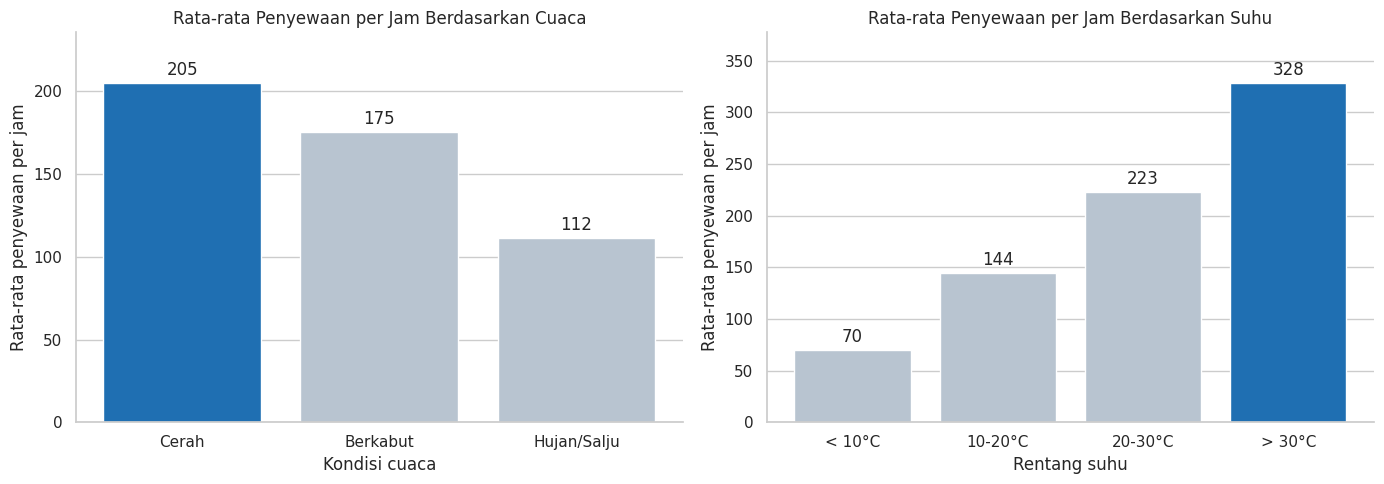

In [28]:
warna_normal, warna_sorot = "#B8C4D0", "#1F6FB2"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Berdasarkan cuaca
cuaca = (hour_df.groupby("weather_group")["cnt"].mean()
         .reindex(["Cerah", "Berkabut", "Hujan/Salju"]))
warna = [warna_sorot] + [warna_normal] * 2
bars = axes[0].bar(cuaca.index, cuaca.values, color=warna)
axes[0].bar_label(bars, fmt="%.0f", padding=3)
axes[0].set_ylim(0, cuaca.max() * 1.15)
axes[0].set_title("Rata-rata Penyewaan per Jam Berdasarkan Cuaca", fontsize=12)
axes[0].set_xlabel("Kondisi cuaca")
axes[0].set_ylabel("Rata-rata penyewaan per jam")

# (b) Berdasarkan suhu
suhu = hour_df.groupby("temp_group", observed=True)["cnt"].mean()
warna = [warna_normal] * (len(suhu) - 1) + [warna_sorot]
bars = axes[1].bar(suhu.index.astype(str), suhu.values, color=warna)
axes[1].bar_label(bars, fmt="%.0f", padding=3)
axes[1].set_ylim(0, suhu.max() * 1.15)
axes[1].set_title("Rata-rata Penyewaan per Jam Berdasarkan Suhu", fontsize=12)
axes[1].set_xlabel("Rentang suhu")
axes[1].set_ylabel("Rata-rata penyewaan per jam")

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Penyewaan saat cuaca cerah (204,9 per jam) 46% lebih tinggi dibanding saat hujan/salju (111,5 per jam), selisih sekitar 93 penyewaan per jam. Cuaca berkabut juga menurunkan penyewaan sekitar 14% dari kondisi cerah.
- Penyewaan naik seiring suhu: dari 70 per jam pada suhu di bawah 10°C menjadi 328 per jam pada suhu di atas 30°C.

### Pertanyaan 2: Pada jam berapa puncak penyewaan di hari kerja vs hari libur, dan bagaimana proporsi casual vs registered?

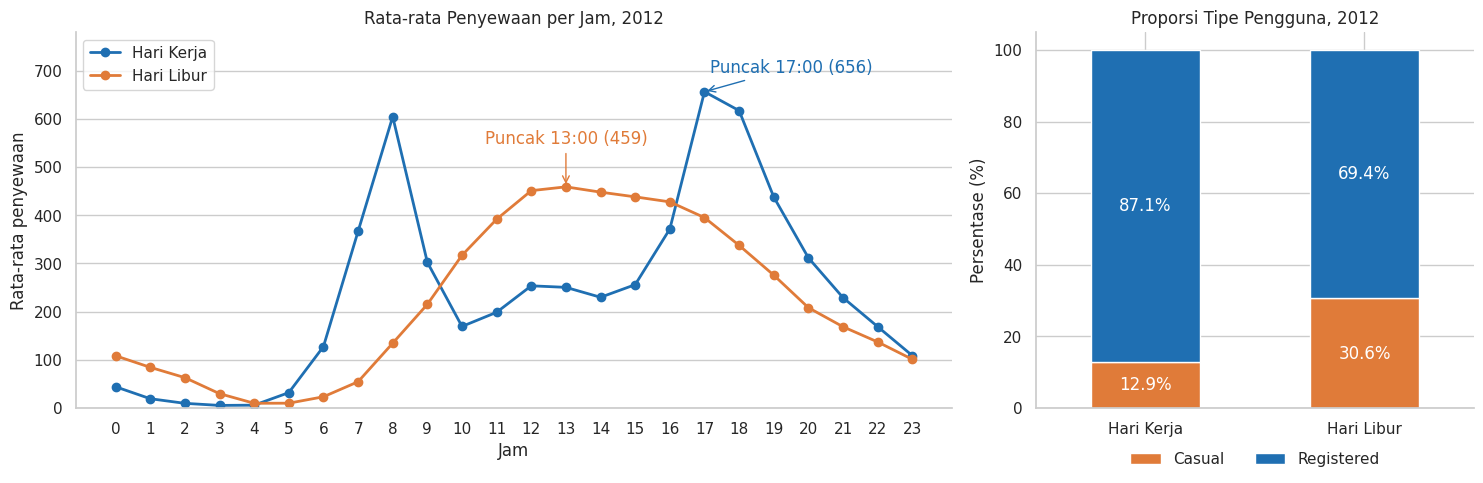

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})

# (a) Pola per jam
for tipe, warna in [("Hari Kerja", "#1F6FB2"), ("Hari Libur", "#E07B39")]:
    data = jam_df[jam_df["day_type"] == tipe]
    axes[0].plot(data["hr"], data["cnt"], marker="o", linewidth=2, color=warna, label=tipe)
    puncak = data.loc[data["cnt"].idxmax()]
    geser = (2.5, 40) if tipe == "Hari Kerja" else (0, 90)
    axes[0].annotate(f"Puncak {int(puncak['hr']):02d}:00 ({puncak['cnt']:.0f})",
                     xy=(puncak["hr"], puncak["cnt"]),
                     xytext=(puncak["hr"] + geser[0], puncak["cnt"] + geser[1]),
                     ha="center", arrowprops=dict(arrowstyle="->", color=warna), color=warna)
axes[0].set_ylim(0, 780)
axes[0].set_xticks(range(0, 24))
axes[0].set_title("Rata-rata Penyewaan per Jam, 2012", fontsize=12)
axes[0].set_xlabel("Jam")
axes[0].set_ylabel("Rata-rata penyewaan")
axes[0].legend(loc="upper left")

# (b) Proporsi casual vs registered
prop = proporsi[["casual_%", "registered_%"]]
prop.plot(kind="bar", stacked=True, ax=axes[1], color=["#E07B39", "#1F6FB2"], rot=0)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", label_type="center", color="white")
axes[1].set_title("Proporsi Tipe Pengguna, 2012", fontsize=12)
axes[1].set_xlabel("")
axes[1].set_ylabel("Persentase (%)")
axes[1].legend(["Casual", "Registered"], loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Hari kerja memiliki dua puncak, yaitu pagi (sekitar jam 08:00, jam berangkat kerja) dan sore, dengan puncak tertinggi pada jam 17:00 (rata-rata 656 penyewaan).
- Hari libur memiliki satu puncak di siang hari, tertinggi pada jam 13:00 (rata-rata 459 penyewaan).
- Pengguna *registered* mendominasi di kedua tipe hari, tetapi porsi *casual* jauh lebih besar saat hari libur (30,6%) dibanding hari kerja (12,9%).

### Pertanyaan 3: Berapa pertumbuhan penyewaan bulanan 2012 dibanding 2011?

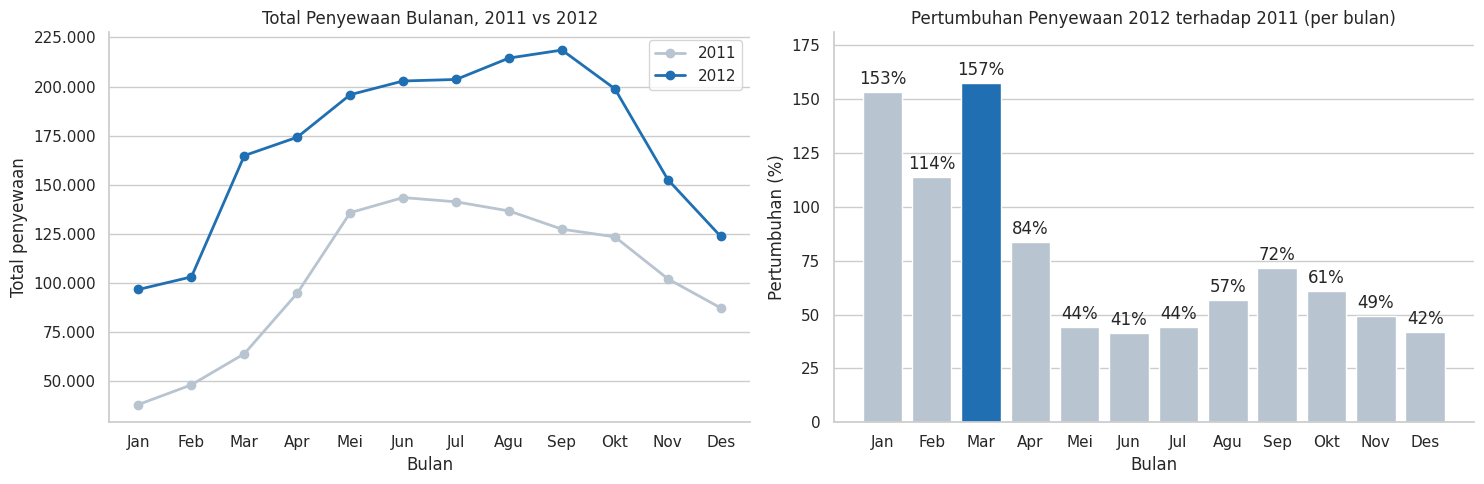

In [30]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Total penyewaan bulanan
axes[0].plot(nama_bulan, bulanan["2011"], marker="o", linewidth=2, color=warna_normal, label="2011")
axes[0].plot(nama_bulan, bulanan["2012"], marker="o", linewidth=2, color=warna_sorot, label="2012")
axes[0].set_title("Total Penyewaan Bulanan, 2011 vs 2012", fontsize=12)
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Total penyewaan")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
axes[0].legend()

# (b) Persentase pertumbuhan
pert = bulanan["pertumbuhan_%"].values
warna = [warna_sorot if v == pert.max() else warna_normal for v in pert]
bars = axes[1].bar(nama_bulan, pert, color=warna)
axes[1].bar_label(bars, fmt="%.0f%%", padding=3)
axes[1].set_ylim(0, pert.max() * 1.15)
axes[1].set_title("Pertumbuhan Penyewaan 2012 terhadap 2011 (per bulan)", fontsize=12)
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Pertumbuhan (%)")

sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Penyewaan 2012 lebih tinggi dari 2011 di semua bulan, dengan pertumbuhan total 64,9%.
- Pertumbuhan tertinggi terjadi pada Maret (157,4%), sedangkan terendah pada Juni (41,3%).
- Persentase pertumbuhan awal tahun tinggi sebagian karena basis penyewaan 2011 masih rendah. Dari sisi volume, penyewaan 2012 tertinggi pada September (218.573) dan terendah pada Januari (96.744).

## Analisis Lanjutan (Opsional)

Teknik yang digunakan adalah **binning / manual grouping**. Jam dikelompokkan menjadi lima kelompok waktu, dan tingkat permintaan per jam dikelompokkan berdasarkan aturan bisnis sederhana: **Rendah** (< 100 penyewaan), **Sedang** (100-299), dan **Tinggi** (≥ 300). RFM dan geospatial tidak digunakan karena dataset tidak memiliki ID pelanggan maupun data lokasi.

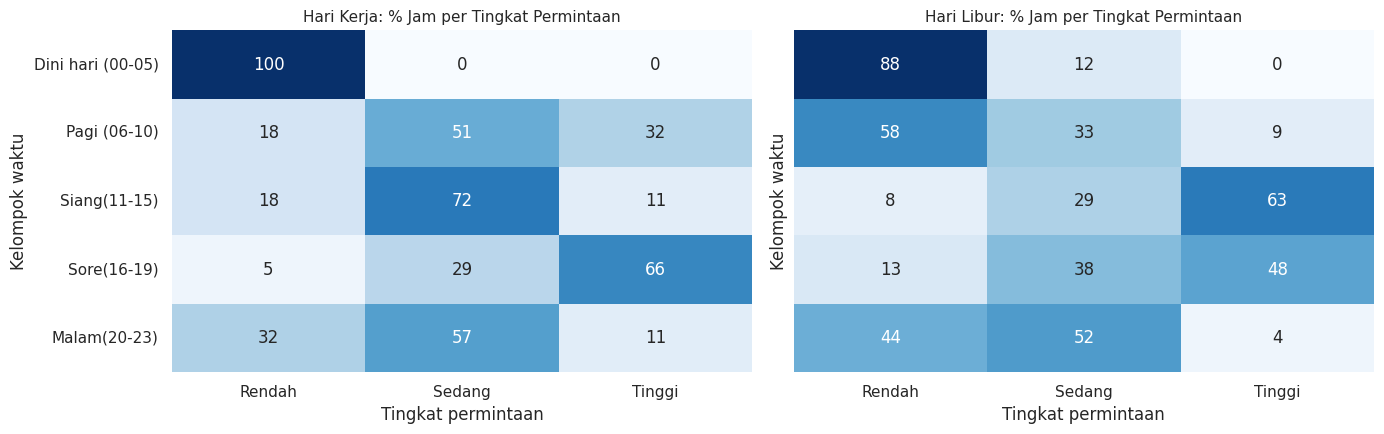

In [31]:
hour_df["demand_level"] = pd.cut(hour_df["cnt"], bins=[0, 100, 300, np.inf],
                                 labels=["Rendah", "Sedang", "Tinggi"], right=False)

# Persentase tingkat permintaan di setiap kelompok waktu, dipisah per tipe hari
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, tipe in zip(axes, ["Hari Kerja", "Hari Libur"]):
    tabel = pd.crosstab(hour_df.loc[hour_df["day_type"] == tipe, "time_group"],
                        hour_df.loc[hour_df["day_type"] == tipe, "demand_level"],
                        normalize="index") * 100
    sns.heatmap(tabel, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{tipe}: % Jam per Tingkat Permintaan", fontsize=11)
    ax.set_xlabel("Tingkat permintaan")
    ax.set_ylabel("Kelompok waktu")
plt.tight_layout()
plt.show()

In [32]:
# Rata-rata penyewaan per kelompok waktu
hour_df.groupby(["day_type", "time_group"], observed=True)["cnt"].mean().round(1).unstack(0)

day_type,Hari Kerja,Hari Libur
time_group,,
Dini hari (00-05),16.4,43.0
Pagi (06-10),249.4,119.2
Siang(11-15),188.5,355.6
Sore(16-19),414.8,297.3
Malam(20-23),165.8,129.7


**Insight:**
- Pada hari kerja, kelompok **Sore (16-19)** paling sering mencapai permintaan *Tinggi* (66% jam), diikuti kelompok Pagi (32%).
- Pada hari libur, permintaan tinggi terkonsentrasi di **Siang (11-15)** (63% jam) dan Sore (48% jam).
- Dini hari berpermintaan rendah hampir sepanjang waktu (100% jam di hari kerja dan 88% di hari libur), sehingga cocok untuk jadwal perawatan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Cuaca dan suhu sangat memengaruhi penyewaan. Rata-rata penyewaan per jam saat cuaca cerah (204,9) lebih tinggi 46% dibanding saat hujan/salju (111,5), selisih sekitar 93 penyewaan per jam, dan lebih tinggi 14% dibanding saat berkabut (175,2). Penyewaan tertinggi terjadi pada suhu di atas 30°C (328 per jam), sedangkan terendah pada suhu di bawah 10°C (70 per jam).
- **Conclusion pertanyaan 2:** Pada 2012, puncak penyewaan hari kerja terjadi pada jam 17:00 (rata-rata 656 penyewaan), dengan puncak kedua di pagi hari sekitar jam 08:00. Puncak hari libur terjadi pada jam 13:00 (rata-rata 459 penyewaan). Pengguna *casual* menyumbang 30,6% penyewaan di hari libur dan 12,9% di hari kerja, sehingga pengguna *registered* mendominasi pola hari kerja.
- **Conclusion pertanyaan 3:** Total penyewaan 2012 tumbuh 64,9% dibanding 2011 dan naik di seluruh bulan. Pertumbuhan bulanan tertinggi pada Maret (157,4%) dan terendah pada Juni (41,3%).

**Rekomendasi Action Item:**
- **Redistribusi sepeda terjadwal:** pastikan stok sepeda di stasiun dekat area perkantoran dan permukiman sudah penuh sebelum jam 07:00 dan 16:00 pada hari kerja, serta di area wisata dan taman sebelum siang pada hari libur.
- **Jadwalkan perawatan di jam sepi:** lakukan servis dan pengecekan armada pada dini hari (00:00-05:00) dan saat cuaca buruk, ketika permintaan paling rendah.
- **Promo saat cuaca kurang mendukung:** tawarkan diskon atau paket khusus pada hari hujan atau berkabut untuk mengurangi penurunan penyewaan, dan siapkan tambahan armada saat cuaca cerah dan hangat.
- **Konversi pengguna casual:** tawarkan promo keanggotaan kepada pengguna *casual* pada akhir pekan, karena porsinya jauh lebih besar di hari libur.
- **Rencanakan kapasitas bulanan:** siapkan armada lebih banyak pada bulan-bulan dengan volume tinggi (musim panas hingga awal gugur), dan gunakan pertumbuhan 2012 sebagai acuan target tahun berikutnya.